
# 02 — RSNA CTA DICOM Visualization

## Step 1: Kaggle Environment and Dataset Verification

### Purpose
Verify that the Kaggle notebook can access the official RSNA Intracranial Aneurysm Detection dataset directly through the Kaggle input directory.

### Method
- Identify the Python environment and working directory.
- Confirm that the RSNA competition dataset is attached.
- Inspect the dataset's top-level directory structure.
- Identify the locations of the training metadata, aneurysm annotations, and medical imaging files.

### Scientific and Technical Importance
The RSNA dataset contains medical images stored in DICOM (Digital Imaging and Communications in Medicine) format.

DICOM files contain both medical image pixel data and metadata, including imaging geometry, acquisition information, and identifiers.

Verifying the dataset structure before image processing ensures that subsequent analyses use the correct files and can be reproduced without downloading the dataset again.


In [2]:
from pathlib import Path

# Kaggle competition datasets directory
competition_dir = Path("/kaggle/input/competitions")

print("=== COMPETITION DATASETS ===")

if competition_dir.exists():
    for item in sorted(competition_dir.iterdir()):
        kind = "DIR" if item.is_dir() else "FILE"
        print(f"[{kind}] {item.name}")

        if item.is_dir():
            print("  Contents:")
            for child in sorted(item.iterdir()):
                child_kind = "DIR" if child.is_dir() else "FILE"
                print(f"  [{child_kind}] {child.name}")
else:
    print("Competition directory not found.")


=== COMPETITION DATASETS ===
[DIR] rsna-intracranial-aneurysm-detection
  Contents:
  [DIR] kaggle_evaluation
  [DIR] segmentations
  [DIR] series
  [FILE] train.csv
  [FILE] train_localizers.csv



### Step 1 — Results and Interpretation

The Kaggle environment and RSNA competition dataset were successfully verified.

**Environment**
- Python version: 3.13.15
- Working directory: `/kaggle/working`
- Dataset directory: `/kaggle/input/competitions/rsna-intracranial-aneurysm-detection`

**Dataset Structure**

The following components were identified:

- `train.csv`: Training metadata and aneurysm classification labels.
- `train_localizers.csv`: Aneurysm localization annotations.
- `series/`: Medical imaging series used for image analysis.
- `segmentations/`: Segmentation-related data.
- `kaggle_evaluation/`: Competition evaluation utilities.

**Interpretation**

The official competition dataset is accessible directly from the Kaggle notebook.

The required metadata and imaging directories are present, allowing further investigation of CTA series without external downloads or API authentication.

The next step is to locate the previously selected positive and negative CTA series and verify their availability.



## Step 2: Locating Selected CTA DICOM Series

### Purpose
Identify the previously selected positive and negative CTA series within the official RSNA dataset and verify that their DICOM files are accessible.

### Method
- Define the dataset root directory.
- Identify the selected series using their SeriesInstanceUID values.
- Search the imaging directory for the corresponding series folders.
- Count the available DICOM files for each series.

### Scientific and Technical Importance
A CT angiography (CTA) scan consists of multiple cross-sectional images acquired during a contrast-enhanced CT examination.

Each imaging series is identified by a unique SeriesInstanceUID, which allows its DICOM images to be grouped correctly.

Confirming that all slices are available is essential before reconstructing a three-dimensional volume. Missing slices may affect anatomical continuity and subsequent image analysis.


In [6]:
from pathlib import Path

SERIES_DIR = Path(
    "/kaggle/input/competitions/"
    "rsna-intracranial-aneurysm-detection/series"
)

positive_uid = (
    "1.2.826.0.1.3680043.8.498."
    "10005158603912009425635473100344077317"
)

negative_uid = (
    "1.2.826.0.1.3680043.8.498."
    "10014757658335054766479957992112625961"
)

positive_dir = SERIES_DIR / positive_uid
negative_dir = SERIES_DIR / negative_uid

print("=== SELECTED CTA SERIES VERIFICATION ===")

for label, folder in [
    ("Positive CTA", positive_dir),
    ("Negative CTA", negative_dir)
]:
    print(f"\n{label}")
    print("Directory exists:", folder.is_dir())

    if folder.is_dir():
        dicom_files = list(folder.glob("*.dcm"))
        print("DICOM file count:", len(dicom_files))
        print(
            "Sample filename:",
            dicom_files[0].name if dicom_files else "None"
        )


=== SELECTED CTA SERIES VERIFICATION ===

Positive CTA
Directory exists: True
DICOM file count: 276
Sample filename: 1.2.826.0.1.3680043.8.498.90015112421437097603956817949043937997.dcm

Negative CTA
Directory exists: True
DICOM file count: 856
Sample filename: 1.2.826.0.1.3680043.8.498.12364464537357970427446244502017251347.dcm



### Step 2 — Results and Interpretation

Both selected CTA series were successfully located in the official RSNA competition dataset.

**Positive CTA Series**
- Aneurysm label: Present (1)
- Series directory: Found
- DICOM files: 276

**Negative CTA Series**
- Aneurysm label: Absent (0)
- Series directory: Found
- DICOM files: 856

**Interpretation**

The observed file counts match the previously recorded counts from our initial dataset exploration.

Both CTA series are accessible directly through the Kaggle input directory, eliminating the need for external downloads.

The positive and negative series contain different numbers of DICOM files. This may reflect differences in scan coverage, acquisition parameters, or image reconstruction.

The file counts confirm the availability of the selected DICOM files, but image integrity and spatial consistency have not yet been verified.

The next step is to inspect DICOM metadata before reconstructing the three-dimensional CTA volumes.



## Step 3: DICOM Metadata Inspection

### Purpose
Examine the metadata of representative DICOM files from the selected positive and negative CTA series to understand their imaging characteristics and spatial information.

### Method
- Read one DICOM file from each selected series using pydicom.
- Extract the imaging modality and DICOM identifiers.
- Examine image dimensions, pixel spacing, slice thickness, and spatial position.
- Inspect pixel intensity conversion parameters.
- Compare the metadata of the positive and negative CTA series.

### Scientific and Technical Importance
DICOM metadata provides essential information for interpreting medical images.

Image dimensions describe the number of pixels in each slice, while PixelSpacing defines the physical size represented by each pixel.

ImagePositionPatient and ImageOrientationPatient describe the spatial location and orientation of the image in the patient coordinate system.

RescaleSlope and RescaleIntercept are used to convert stored CT pixel values into calibrated intensity values, commonly expressed in Hounsfield Units (HU).

Understanding these parameters is essential for accurate 3D reconstruction, visualization, preprocessing, and subsequent deep learning analysis.


In [7]:
import pydicom

print("=== DICOM METADATA INSPECTION ===")

for label, folder in [
    ("Positive CTA", positive_dir),
    ("Negative CTA", negative_dir)
]:
    dicom_files = sorted(folder.glob("*.dcm"))

    if not dicom_files:
        print(f"\n{label}: No DICOM files found.")
        continue

    # Read metadata without loading pixel data
    ds = pydicom.dcmread(
        str(dicom_files[0]),
        stop_before_pixels=True
    )

    print(f"\n=== {label} ===")

    fields = {
        "Modality": ds.get("Modality", "N/A"),
        "SeriesInstanceUID": ds.get("SeriesInstanceUID", "N/A"),
        "SOPInstanceUID": ds.get("SOPInstanceUID", "N/A"),
        "Rows": ds.get("Rows", "N/A"),
        "Columns": ds.get("Columns", "N/A"),
        "PixelSpacing": ds.get("PixelSpacing", "N/A"),
        "SliceThickness": ds.get("SliceThickness", "N/A"),
        "SpacingBetweenSlices": ds.get("SpacingBetweenSlices", "N/A"),
        "ImagePositionPatient": ds.get("ImagePositionPatient", "N/A"),
        "ImageOrientationPatient": ds.get("ImageOrientationPatient", "N/A"),
        "RescaleSlope": ds.get("RescaleSlope", "N/A"),
        "RescaleIntercept": ds.get("RescaleIntercept", "N/A")
    }

    for key, value in fields.items():
        print(f"{key}: {value}")


=== DICOM METADATA INSPECTION ===

=== Positive CTA ===
Modality: CT
SeriesInstanceUID: 1.2.826.0.1.3680043.8.498.10005158603912009425635473100344077317
SOPInstanceUID: 1.2.826.0.1.3680043.8.498.10003397430845295846773533938883941118
Rows: 512
Columns: 512
PixelSpacing: [0.439453125, 0.439453125]
SliceThickness: 0.6
SpacingBetweenSlices: N/A
ImagePositionPatient: [-112.2802734375, -279.7802734375, -91]
ImageOrientationPatient: [1, 0, 0, 0, 1, 0]
RescaleSlope: N/A
RescaleIntercept: N/A

=== Negative CTA ===
Modality: CT
SeriesInstanceUID: 1.2.826.0.1.3680043.8.498.10014757658335054766479957992112625961
SOPInstanceUID: 1.2.826.0.1.3680043.8.498.10013214056090248683959778205558941059
Rows: 512
Columns: 512
PixelSpacing: [0.48828125, 0.48828125]
SliceThickness: 0.8
SpacingBetweenSlices: 0.4
ImagePositionPatient: [-134, 32.5, 148.37]
ImageOrientationPatient: [1, 0, 0, 0, 1, 0]
RescaleSlope: N/A
RescaleIntercept: N/A



### Step 3 — Results and Interpretation

DICOM metadata was successfully extracted from one representative image in each selected CTA series using pydicom.

**Imaging Characteristics**

| Parameter | Positive CTA | Negative CTA |
|---|---|---|
| Modality | CT | CT |
| Image dimensions | 512 × 512 | 512 × 512 |
| Pixel spacing (mm) | 0.43945 × 0.43945 | 0.48828 × 0.48828 |
| Slice thickness (mm) | 0.6 | 0.8 |
| SpacingBetweenSlices (mm) | Not available | 0.4 |
| Image orientation | [1, 0, 0, 0, 1, 0] | [1, 0, 0, 0, 1, 0] |
| RescaleSlope | Not available | Not available |
| RescaleIntercept | Not available | Not available |

**Interpretation**

Both series contain 512 × 512 CT images with standard axial orientation.

The positive CTA has a smaller in-plane pixel spacing (approximately 0.439 mm) than the negative CTA (approximately 0.488 mm), indicating differences in spatial sampling resolution.

The slice thickness also differs between the two series (0.6 mm versus 0.8 mm).

These differences demonstrate that medical images from different acquisitions may have different spatial resolutions, even when their pixel dimensions are identical.

RescaleSlope and RescaleIntercept were absent from the inspected DICOM files. Therefore, the interpretation of stored pixel intensities must be verified before treating them as Hounsfield Units.

**Conclusion**

The representative DICOM metadata is accessible and contains essential spatial information.

Before reconstructing the complete CTA volumes, slice ordering, spatial spacing, metadata consistency, and pixel intensity interpretation must be examined.



## Step 4: Slice Ordering and Spatial Integrity Verification

### Purpose
Verify the spatial organization and consistency of the selected positive and negative CTA series before three-dimensional volume reconstruction.

### Method
- Read the DICOM metadata from all slices in each series without loading pixel arrays.
- Extract image positions and orientations.
- Calculate slice positions along the image-plane normal.
- Sort slices according to their spatial positions.
- Identify duplicate slice positions and irregular spacing.
- Verify image dimensions and pixel spacing consistency.

### Scientific and Technical Importance
A three-dimensional CTA volume is reconstructed by stacking individual two-dimensional CT images in their correct anatomical order.

DICOM filenames do not necessarily represent the physical order of the slices.

ImagePositionPatient and ImageOrientationPatient provide the spatial information needed to determine slice ordering.

Incorrect slice ordering, duplicated positions, or inconsistent spacing may distort the reconstructed anatomy and affect subsequent aneurysm detection.

Spatial integrity verification is therefore an essential quality-control step before medical image reconstruction and deep learning preprocessing.


In [8]:
import numpy as np
import pydicom

print("=== CTA SPATIAL INTEGRITY VERIFICATION ===")

for label, folder in [
    ("Positive CTA", positive_dir),
    ("Negative CTA", negative_dir)
]:
    files = sorted(folder.glob("*.dcm"))

    records = []
    dimensions = set()
    pixel_spacings = set()
    orientations = set()
    missing_positions = 0

    for file in files:
        ds = pydicom.dcmread(
            str(file),
            stop_before_pixels=True
        )

        if not hasattr(ds, "ImagePositionPatient") or not hasattr(
            ds, "ImageOrientationPatient"
        ):
            missing_positions += 1
            continue

        position = np.array(
            ds.ImagePositionPatient, dtype=float
        )

        orientation = np.array(
            ds.ImageOrientationPatient, dtype=float
        )

        row_direction = orientation[:3]
        column_direction = orientation[3:]

        normal = np.cross(row_direction, column_direction)

        slice_position = np.dot(position, normal)

        records.append((slice_position, file.name))

        dimensions.add((int(ds.Rows), int(ds.Columns)))
        pixel_spacings.add(
            tuple(float(x) for x in ds.PixelSpacing)
        )
        orientations.add(tuple(orientation))

    positions = np.array(
        sorted(record[0] for record in records)
    )

    differences = np.diff(positions)

    duplicate_count = int(
        np.sum(np.isclose(differences, 0, atol=1e-4))
    )

    print(f"\n=== {label} ===")
    print("Total DICOM files:", len(files))
    print("Valid spatial positions:", len(positions))
    print("Missing spatial metadata:", missing_positions)

    print("Image dimensions:", dimensions)
    print("Pixel spacings:", pixel_spacings)
    print("Unique orientations:", len(orientations))

    if len(positions) > 1:
        print("Minimum slice position (mm):", positions.min())
        print("Maximum slice position (mm):", positions.max())

        print("Minimum spacing (mm):", differences.min())
        print("Median spacing (mm):", np.median(differences))
        print("Maximum spacing (mm):", differences.max())

        print("Duplicate positions:", duplicate_count)

        print(
            "Unique rounded spacings (mm):",
            np.unique(np.round(differences, 3))[:20]
        )


=== CTA SPATIAL INTEGRITY VERIFICATION ===

=== Positive CTA ===
Total DICOM files: 276
Valid spatial positions: 276
Missing spatial metadata: 0
Image dimensions: {(512, 512)}
Pixel spacings: {(0.439453125, 0.439453125)}
Unique orientations: 1
Minimum slice position (mm): -161.8
Maximum slice position (mm): -51.8
Minimum spacing (mm): 0.39999999999997726
Median spacing (mm): 0.4000000000000057
Maximum spacing (mm): 0.4000000000000057
Duplicate positions: 0
Unique rounded spacings (mm): [0.4]

=== Negative CTA ===
Total DICOM files: 856
Valid spatial positions: 856
Missing spatial metadata: 0
Image dimensions: {(512, 512)}
Pixel spacings: {(0.48828125, 0.48828125)}
Unique orientations: 1
Minimum slice position (mm): 52.77
Maximum slice position (mm): 394.77
Minimum spacing (mm): 0.39999999999997726
Median spacing (mm): 0.4000000000000057
Maximum spacing (mm): 0.4000000000000341
Duplicate positions: 0
Unique rounded spacings (mm): [0.4]



### Step 4 — Results and Interpretation

Spatial integrity verification was completed for both selected CTA series.

| Parameter | Positive CTA | Negative CTA |
|---|---|---|
| Total DICOM files | 276 | 856 |
| Valid spatial positions | 276 | 856 |
| Missing spatial metadata | 0 | 0 |
| Image dimensions | 512 × 512 | 512 × 512 |
| Pixel spacing (mm) | 0.43945 × 0.43945 | 0.48828 × 0.48828 |
| Unique orientations | 1 | 1 |
| Slice spacing (mm) | 0.4 | 0.4 |
| Duplicate positions | 0 | 0 |
| Irregular spacing detected | No | No |

**Spatial Coverage**

- Positive CTA: -161.8 mm to -51.8 mm (110 mm)
- Negative CTA: 52.77 mm to 394.77 mm (342 mm)

**Interpretation**

All 276 positive and 856 negative CTA DICOM files contain valid spatial positioning metadata.

Both series have consistent image dimensions, pixel spacing, and image orientation.

The calculated distance between consecutive slice centers is 0.4 mm for both series.

No duplicate spatial positions or irregular spacing were detected.

Although the slice thickness differs between the scans, both series have identical inter-slice center spacing.

The negative series covers a substantially larger distance along the slice-normal direction than the positive series.

**Conclusion**

Both selected CTA series passed the spatial consistency checks performed in this step.

The slices can now be arranged according to their physical positions for three-dimensional reconstruction.

Further verification of pixel data and intensity calibration is required before quantitative image analysis.



## Step 5: Three-Dimensional CTA Volume Reconstruction

### Purpose
Reconstruct the selected positive and negative CTA series into three-dimensional NumPy arrays using their DICOM pixel data and spatial coordinates.

### Method
- Read all DICOM files from each selected CTA series.
- Extract the pixel arrays using pydicom.
- Sort the images according to their physical positions.
- Stack the ordered two-dimensional images into three-dimensional volumes.
- Inspect volume dimensions, data types, memory usage, and stored pixel intensity ranges.

### Scientific and Technical Importance
CT angiography produces multiple two-dimensional cross-sectional images that collectively represent three-dimensional anatomy.

Correct reconstruction requires arranging the images according to their spatial positions rather than filenames.

The resulting three-dimensional arrays allow visualization of anatomical structures in axial, coronal, and sagittal planes.

Pixel intensities must be interpreted carefully because stored DICOM values are not necessarily calibrated Hounsfield Units.

Three-dimensional reconstruction is a fundamental preparation step for medical image visualization and subsequent deep learning analysis.


In [9]:
import numpy as np
import pydicom

def reconstruct_cta_volume(folder):
    slices = []

    for file in folder.glob("*.dcm"):
        ds = pydicom.dcmread(str(file))

        orientation = np.asarray(
            ds.ImageOrientationPatient, dtype=float
        )
        normal = np.cross(
            orientation[:3], orientation[3:]
        )

        position = np.asarray(
            ds.ImagePositionPatient, dtype=float
        )

        slice_location = float(np.dot(position, normal))

        pixels = ds.pixel_array

        slices.append((slice_location, pixels))

    # Sort by physical slice position
    slices.sort(key=lambda item: item[0])

    # Stack images into a 3D volume
    volume = np.stack(
        [item[1] for item in slices],
        axis=0
    )

    positions = np.array(
        [item[0] for item in slices]
    )

    return volume, positions


print("=== POSITIVE CTA RECONSTRUCTION ===")

positive_volume, positive_positions = reconstruct_cta_volume(
    positive_dir
)

print("Shape:", positive_volume.shape)
print("Data type:", positive_volume.dtype)
print("Minimum stored intensity:", positive_volume.min())
print("Maximum stored intensity:", positive_volume.max())
print("Memory usage (MiB):", round(
    positive_volume.nbytes / (1024 ** 2), 2
))


print("\n=== NEGATIVE CTA RECONSTRUCTION ===")

negative_volume, negative_positions = reconstruct_cta_volume(
    negative_dir
)

print("Shape:", negative_volume.shape)
print("Data type:", negative_volume.dtype)
print("Minimum stored intensity:", negative_volume.min())
print("Maximum stored intensity:", negative_volume.max())
print("Memory usage (MiB):", round(
    negative_volume.nbytes / (1024 ** 2), 2
))


=== POSITIVE CTA RECONSTRUCTION ===
Shape: (276, 512, 512)
Data type: int16
Minimum stored intensity: -1024
Maximum stored intensity: 3029
Memory usage (MiB): 138.0

=== NEGATIVE CTA RECONSTRUCTION ===
Shape: (856, 512, 512)
Data type: int16
Minimum stored intensity: -1024
Maximum stored intensity: 3071
Memory usage (MiB): 428.0



### Step 5 — Results and Interpretation

Both selected CTA series were successfully reconstructed into three-dimensional NumPy arrays using pydicom and NumPy.

**Reconstructed Volume Characteristics**

| Parameter | Positive CTA | Negative CTA |
|---|---|---|
| Volume shape | (276, 512, 512) | (856, 512, 512) |
| Number of slices | 276 | 856 |
| Image dimensions | 512 × 512 | 512 × 512 |
| Data type | int16 | int16 |
| Minimum stored intensity | -1024 | -1024 |
| Maximum stored intensity | 3029 | 3071 |
| Memory usage | 138 MiB | 428 MiB |

**Interpretation**

The positive and negative CTA series were reconstructed by sorting DICOM images according to their physical positions and stacking their pixel arrays.

The resulting volumes have three dimensions:
- Axis 0: Slice index
- Axis 1: Image row
- Axis 2: Image column

Both volumes contain 512 × 512 pixel images, but the negative CTA has more slices and covers a larger anatomical region.

The reconstructed arrays use the int16 data type, which stores signed 16-bit integers and requires 2 bytes per voxel.

The combined memory usage of the two reconstructed volumes is approximately 566 MiB.

The observed intensity ranges represent decoded stored pixel values. Their interpretation as Hounsfield Units requires confirmation of the relevant DICOM intensity calibration metadata.

**Conclusion**

Both CTA volumes were successfully reconstructed and are available for further image analysis.

The next step is to visualize the reconstructed anatomy in axial, coronal, and sagittal planes.



## Step 6: Multiplanar Visualization of Reconstructed CTA Volumes

### Purpose
Visualize the reconstructed positive and negative CTA volumes in axial, coronal, and sagittal planes to examine their anatomical structures and assess image reconstruction quality.

### Method
- Select representative central slices from each reconstructed volume.
- Extract axial, coronal, and sagittal views using NumPy array indexing.
- Apply a consistent grayscale display window for initial visualization.
- Compare the anatomical appearance of the positive and negative CTA scans.

### Scientific and Technical Importance
Multiplanar reconstruction (MPR) allows three-dimensional medical imaging data to be examined from different anatomical directions.

The axial plane divides the body into superior and inferior regions.

The coronal plane divides the body into anterior and posterior regions.

The sagittal plane divides the body into left and right regions.

Examining all three planes helps assess anatomical continuity, image orientation, and reconstruction quality.

A fixed display intensity range is used for initial visualization. Because intensity calibration has not yet been fully verified, this range should not be interpreted as a validated Hounsfield Unit window.


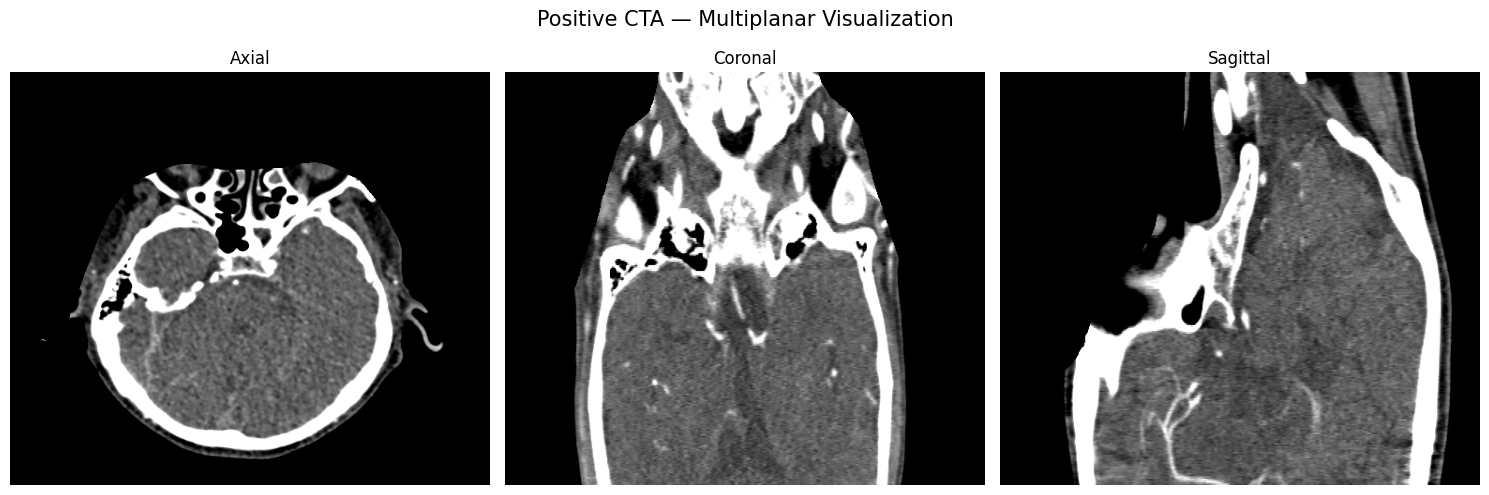

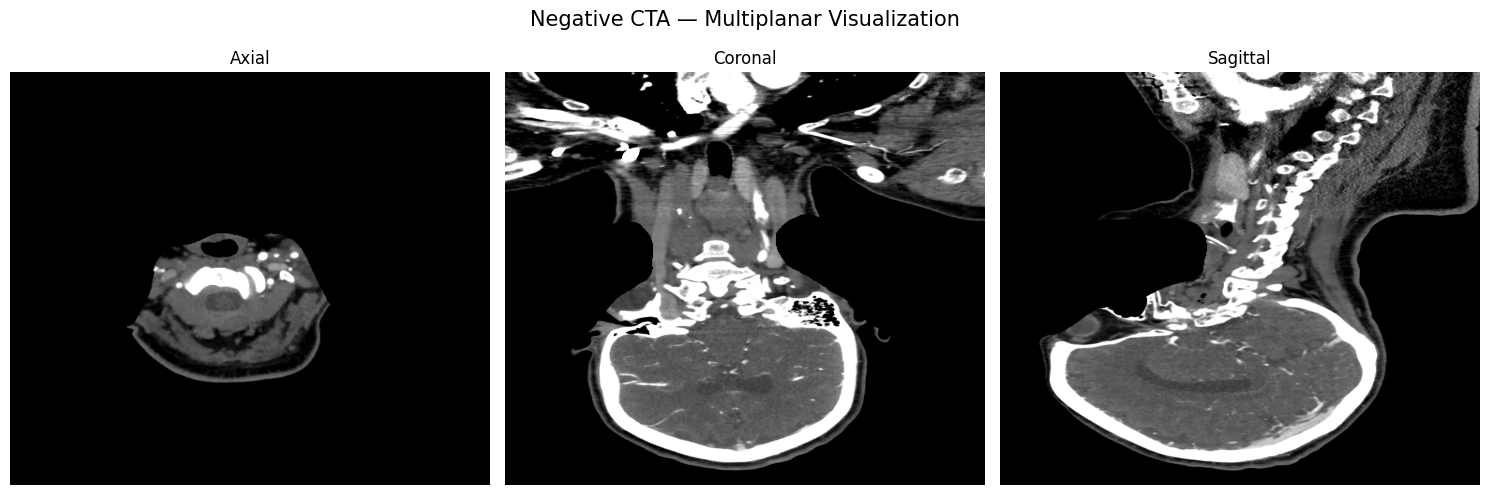

In [10]:

import numpy as np
import matplotlib.pyplot as plt

def visualize_cta_planes(volume, title):
    # Select central slices
    z = volume.shape[0] // 2
    y = volume.shape[1] // 2
    x = volume.shape[2] // 2

    axial = volume[z, :, :]
    coronal = volume[:, y, :]
    sagittal = volume[:, :, x]

    views = [
        ("Axial", axial),
        ("Coronal", coronal),
        ("Sagittal", sagittal)
    ]

    fig, axes = plt.subplots(
        1, 3, figsize=(15, 5)
    )

    for ax, (name, image) in zip(axes, views):
        ax.imshow(
            image,
            cmap="gray",
            vmin=-100,
            vmax=300,
            aspect="auto"
        )

        ax.set_title(name)
        ax.axis("off")

    fig.suptitle(title, fontsize=15)
    plt.tight_layout()
    plt.show()


visualize_cta_planes(
    positive_volume,
    "Positive CTA — Multiplanar Visualization"
)

visualize_cta_planes(
    negative_volume,
    "Negative CTA — Multiplanar Visualization"
)



### Step 6 — Results and Interpretation

Multiplanar visualization was successfully performed for both reconstructed CTA volumes.

**Positive CTA**
- The axial view displays intracranial structures and the skull base.
- The coronal and sagittal views demonstrate anatomical continuity across the reconstructed volume.
- Contrast-enhanced vascular structures are visible.

**Negative CTA**
- The central axial view displays cervical anatomy rather than the intracranial region.
- The coronal and sagittal views show a larger anatomical coverage, including the neck and portions of the head.
- The differences in anatomical coverage are consistent with the larger number of slices in the negative series.

**Interpretation**

Both CTA volumes can be visualized in three orthogonal planes, supporting the correctness of the basic slice stacking procedure.

However, selecting the central slice does not guarantee that the same anatomical region will be displayed across different scans.

The current visualization uses a fixed stored-intensity display range and does not preserve the physical aspect ratio of the reconstructed images.

**Conclusion**

The initial multiplanar visualization was completed successfully.

Future visualization and preprocessing should account for differences in anatomical coverage, voxel spacing, image orientation, and intensity calibration.

The next step is to identify the annotated aneurysm location in the positive CTA series using the provided localization metadata.



## Step 7: Matching Aneurysm Localization Annotations to DICOM Images

### Purpose
Identify the annotated intracranial aneurysm in the selected positive CTA series and match its localization metadata to the corresponding DICOM image.

### Method
- Load the aneurysm localization metadata from train_localizers.csv.
- Identify the annotation associated with the selected positive SeriesInstanceUID.
- Extract the annotated SOPInstanceUID and image coordinates.
- Locate the corresponding DICOM file within the positive CTA series.
- Verify that the annotation coordinates fall within the image dimensions.

### Scientific and Technical Importance
An intracranial aneurysm is an abnormal dilation of an intracranial artery.

The RSNA dataset provides localization annotations that identify image locations associated with aneurysms.

SeriesInstanceUID identifies the imaging series, while SOPInstanceUID identifies a particular DICOM image instance.

Matching these identifiers allows the annotation to be associated with the correct medical image.

Accurate annotation matching is essential for aneurysm visualization, localization analysis, and future supervised deep learning applications.


In [12]:

import pandas as pd
import pydicom
import ast

# Load localization metadata
localizers = pd.read_csv(
    DATA_DIR / "train_localizers.csv"
)

# Select annotations for the positive CTA series
positive_annotations = localizers[
    localizers["SeriesInstanceUID"].astype(str) == positive_uid
].copy()

print("=== POSITIVE CTA ANNOTATION VERIFICATION ===")
print("Number of annotations:", len(positive_annotations))

for _, annotation in positive_annotations.iterrows():

    sop_uid = str(annotation["SOPInstanceUID"])
    dicom_path = positive_dir / f"{sop_uid}.dcm"

    # Convert coordinate string to dictionary
    coordinates = ast.literal_eval(
        annotation["coordinates"]
    )

    x = float(coordinates["x"])
    y = float(coordinates["y"])

    print("\n=== ANNOTATION DETAILS ===")
    print("Anatomical location:", annotation["location"])
    print("SOPInstanceUID:", sop_uid)
    print("Annotation X:", x)
    print("Annotation Y:", y)

    print("\n=== DICOM VERIFICATION ===")
    print("DICOM file exists:", dicom_path.is_file())

    if dicom_path.is_file():

        ds = pydicom.dcmread(
            str(dicom_path),
            stop_before_pixels=True
        )

        print(
            "Series UID matches:",
            str(ds.SeriesInstanceUID) == positive_uid
        )

        print(
            "SOP UID matches:",
            str(ds.SOPInstanceUID) == sop_uid
        )

        print("Image dimensions:", (ds.Rows, ds.Columns))
        print("Image position:", ds.ImagePositionPatient)

        within_bounds = (
            0 <= x < ds.Columns
            and 0 <= y < ds.Rows
        )

        print("Coordinates within image:", within_bounds)


=== POSITIVE CTA ANNOTATION VERIFICATION ===
Number of annotations: 1

=== ANNOTATION DETAILS ===
Anatomical location: Other Posterior Circulation
SOPInstanceUID: 1.2.826.0.1.3680043.8.498.10775329348174902199350466348663848346
Annotation X: 258.3621186176837
Annotation Y: 261.359900373599

=== DICOM VERIFICATION ===
DICOM file exists: True
Series UID matches: True
SOP UID matches: True
Image dimensions: (512, 512)
Image position: [-112.2802734375, -279.7802734375, -97]
Coordinates within image: True



### Step 7 — Results and Interpretation

The aneurysm localization annotation was successfully matched to the corresponding DICOM image in the positive CTA series.

**Annotation Details**
- Number of matching annotations: 1
- Anatomical location: Other Posterior Circulation
- X coordinate: 258.3621 pixels
- Y coordinate: 261.3599 pixels
- Image dimensions: 512 × 512 pixels
- Image position (mm): [-112.2803, -279.7803, -97.0]

**Verification Results**
- Corresponding DICOM file exists: True
- SeriesInstanceUID matches: True
- SOPInstanceUID matches: True
- Annotation coordinates within image boundaries: True

**Interpretation**

The localization metadata identifies a specific DICOM image and an associated pixel coordinate within the positive CTA series.

The matching SeriesInstanceUID and SOPInstanceUID confirm that the annotation is associated with the intended image.

The annotation coordinates fall within the valid 512 × 512 image boundaries.

The anatomical location is labeled "Other Posterior Circulation," indicating an aneurysm associated with the posterior cerebral vascular circulation.

**Conclusion**

The annotation-to-image matching procedure was successful.

The annotated DICOM image is ready for visualization with its localization marker.

The annotation provides a reference location rather than a complete aneurysm segmentation.



## Step 8: Visualization of the Annotated Intracranial Aneurysm

### Purpose
Visualize the DICOM image containing the annotated intracranial aneurysm and highlight its reference location within the CTA scan.

### Method
- Retrieve the DICOM image using the annotated SOPInstanceUID.
- Extract the image pixel array using pydicom.
- Extract the corresponding X and Y annotation coordinates.
- Display the original axial CTA image with an annotation marker.
- Generate a magnified view centered on the annotated location.

### Scientific and Technical Importance
Intracranial aneurysms are localized dilations of cerebral arteries that may be difficult to distinguish from normal vascular structures in individual CT slices.

Localization annotations provide reference points for examining suspected aneurysm regions.

Displaying the annotation on the corresponding CTA image helps verify the relationship between imaging data and ground-truth labels.

Magnified visualization allows closer inspection of local vascular anatomy and supports preparation for subsequent image preprocessing and deep learning analysis.

The annotation represents a reference location and does not define the complete aneurysm boundary.


=== ANNOTATED CTA IMAGE ===
Image shape: (512, 512)
Stored intensity range: -1024 2680
Annotation location: (258.3621186176837, 261.359900373599)
Anatomical region: Other Posterior Circulation


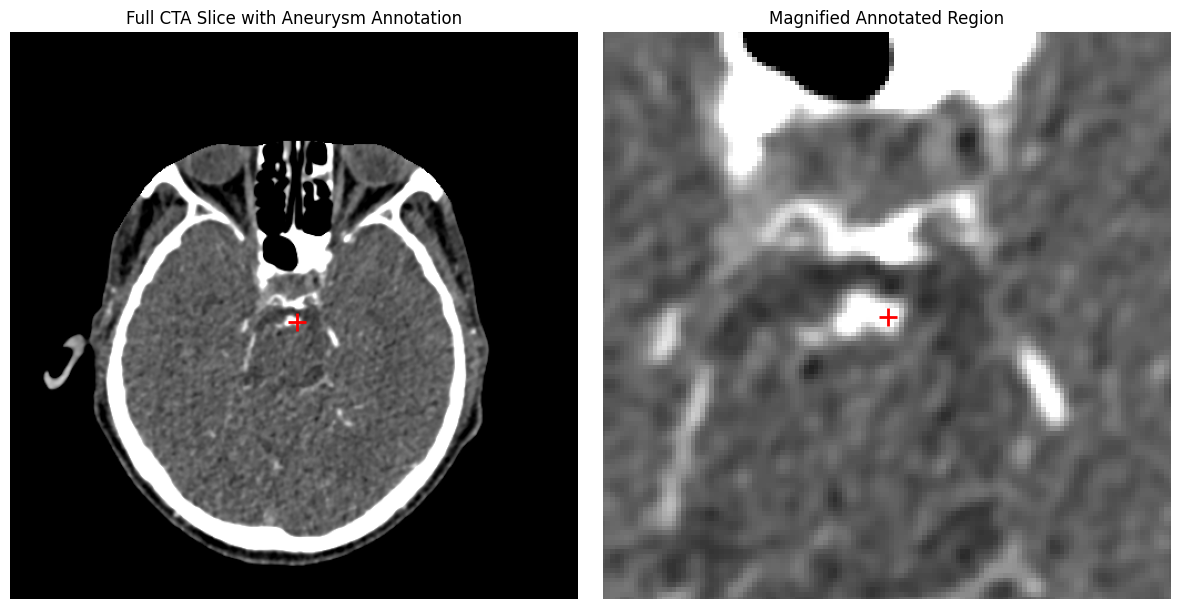

In [13]:
import matplotlib.pyplot as plt
import pydicom
import ast
import numpy as np

# Retrieve the verified annotation
annotation = positive_annotations.iloc[0]

sop_uid = str(annotation["SOPInstanceUID"])
coordinates = ast.literal_eval(annotation["coordinates"])

x = float(coordinates["x"])
y = float(coordinates["y"])

# Read the annotated DICOM image
dicom_path = positive_dir / f"{sop_uid}.dcm"
ds = pydicom.dcmread(str(dicom_path))

image = ds.pixel_array

print("=== ANNOTATED CTA IMAGE ===")
print("Image shape:", image.shape)
print("Stored intensity range:", image.min(), image.max())
print("Annotation location:", (x, y))
print("Anatomical region:", annotation["location"])

# Define zoom region around annotation
zoom_radius = 60

x_min = max(0, int(x) - zoom_radius)
x_max = min(image.shape[1], int(x) + zoom_radius)

y_min = max(0, int(y) - zoom_radius)
y_max = min(image.shape[0], int(y) + zoom_radius)

# Create visualization
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Full CTA image
axes[0].imshow(
    image,
    cmap="gray",
    vmin=-100,
    vmax=300
)

axes[0].scatter(
    x, y,
    color="red",
    marker="+",
    s=150,
    linewidths=2
)

axes[0].set_title("Full CTA Slice with Aneurysm Annotation")
axes[0].axis("off")

# Magnified aneurysm region
axes[1].imshow(
    image,
    cmap="gray",
    vmin=-100,
    vmax=300
)

axes[1].scatter(
    x, y,
    color="red",
    marker="+",
    s=180,
    linewidths=2
)

axes[1].set_xlim(x_min, x_max)
axes[1].set_ylim(y_max, y_min)

axes[1].set_title("Magnified Annotated Region")
axes[1].axis("off")

plt.tight_layout()
plt.show()



### Step 8 — Results and Interpretation

The annotated DICOM image from the positive CTA series was successfully visualized using pydicom and Matplotlib.

**Image Characteristics**
- Image dimensions: 512 × 512 pixels
- Stored intensity range: -1024 to 2680
- Annotation coordinates: X = 258.36, Y = 261.36
- Anatomical label: Other Posterior Circulation
- DICOM image position: Z = -97 mm

**Visualization Results**

The full axial CTA image displays the intracranial anatomy at the annotated slice position.

The red cross indicates the localization coordinate supplied by the RSNA dataset.

A magnified region centered on the annotation reveals a small, relatively bright structure near the central skull-base vascular region.

**Interpretation**

The annotation was successfully mapped to the corresponding DICOM image using SeriesInstanceUID, SOPInstanceUID, and pixel coordinates.

The visualization confirms that the localization marker can be displayed within the appropriate image boundaries.

The magnified image provides a closer view of the annotated vascular region, but a single slice is insufficient to determine the complete aneurysm morphology.

The annotation represents a reference location rather than a segmentation of the aneurysm.

**Conclusion**

The annotated aneurysm location was successfully visualized in the positive CTA series.

This completes the initial DICOM reconstruction, multiplanar visualization, and annotation-matching objectives for the selected CTA examples.

Further work should include intensity calibration verification, visualization of neighboring slices, and preparation of a leakage-safe patient-level training and validation split.
